In [105]:
# Library
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import xgboost as xgb
from pathlib import Path
import os

import warnings
warnings.filterwarnings('ignore')
print(os.getcwd())

/home/yahia/gci_world-2026/notebooks


In [106]:
# Read the file 
client = pd.read_csv('../data/raw/Client.csv')
record = pd.read_csv('../data/raw/Record.csv')

In [107]:
# Dispaly data content of the (Client) dataset
print(f"Number of columns and rows: {client.shape}")
print(f"Show the first 5 columns: {client.head()}")

Number of columns and rows: (100000, 50)
Show the first 5 columns:    uniqsubs  actvsubs new_cell crclscod asl_flag  totcalls       totmou  \
0         2         1        U        A        N      1652   4228.00000   
1         1         1        N       EA        N     14654  26400.00000   
2         1         1        Y        C        N      7903  24385.05333   
3         1         1        Y        B        N      1502   3065.00000   
4         1         1        Y        A        N      4485  14028.00000   

    totrev   adjrev    adjmou  ...  forgntvl  ethnic  kid0_2  kid3_5  kid6_10  \
0  1504.62  1453.44   4085.00  ...       0.0       N       U       U        U   
1  2851.68  2833.88  26367.00  ...       0.0       Z       U       U        U   
2  2155.91  1934.47  24303.05  ...       0.0       N       U       Y        U   
3  2000.90  1941.81   3035.00  ...       0.0       U       Y       U        U   
4  2181.12  2166.48  13965.00  ...       0.0       I       U       U        U

In [108]:
# Dispaly data content of the (record) dataste
print(f"Number of columns and row: {record.shape}")
print(f"Show the first 5 columns: {record.head()}")

Number of columns and row: (100000, 51)
Show the first 5 columns:    rev_Mean  mou_Mean  totmrc_Mean  da_Mean  ovrmou_Mean  ovrrev_Mean  \
0   23.9975    219.25       22.500   0.2475         0.00          0.0   
1   57.4925    482.75       37.425   0.2475        22.75          9.1   
2   16.9900     10.25       16.990   0.0000         0.00          0.0   
3   38.0000      7.50       38.000   0.0000         0.00          0.0   
4   55.2300    570.50       71.980   0.0000         0.00          0.0   

   vceovr_Mean  datovr_Mean  roam_Mean  change_mou  ...  mou_opkv_Mean  \
0          0.0          0.0        0.0     -157.25  ...      55.220000   
1          9.1          0.0        0.0      532.25  ...     169.343333   
2          0.0          0.0        0.0       -4.25  ...       0.233333   
3          0.0          0.0        0.0       -1.50  ...       5.450000   
4          0.0          0.0        0.0       38.50  ...     218.086667   

   mou_opkd_Mean  drop_blk_Mean  attempt_Mean  com

In [109]:
# Porporation of missing values of the file (cilent and record)
missing_value_client = client.isnull().sum() / client.shape[0]
print(f"Missing values in the file client:\n {missing_value_client.sort_values(ascending=False).head(10)}")

missing_value_record = record.isnull().sum() / record.shape[0]
print(f"Missing values in the record file: \n {missing_value_record.sort_values(ascending=False).head(10)}")

Missing values in the file client:
 numbcars      0.49366
dwllsize      0.38308
HHstatin      0.37923
ownrent       0.33706
dwlltype      0.31909
lor           0.30190
income        0.25436
adults        0.23019
infobase      0.22079
hnd_webcap    0.10189
dtype: float64
Missing values in the record file: 
 change_mou     0.00891
change_rev     0.00891
rev_Mean       0.00357
totmrc_Mean    0.00357
mou_Mean       0.00357
da_Mean        0.00357
ovrmou_Mean    0.00357
vceovr_Mean    0.00357
ovrrev_Mean    0.00357
roam_Mean      0.00357
dtype: float64


In [110]:
# Cleaning up the data in the client file
cols_high_missing = ['numbcars', 'dwllsize', 'HHstatin', 'ownrent', 'dwlltype']

for col in cols_high_missing:
    client[f'{col}_is_missing'] = client[col].isnull().astype(int)

client['numbcars'] = client['numbcars'].fillna(0)
client['dwllsize'] = client['dwllsize'].fillna(0)

client['HHstatin'] = client['HHstatin'].fillna('Unknown')
client['ownrent'] = client['ownrent'].fillna('Unknown')
client['dwlltype'] = client['dwlltype'].fillna('Unknown')

print("The columns with the highest data loss in the client file have been processed.")

The columns with the highest data loss in the client file have been processed.


In [111]:
# Cleaning up the data in the record file 
# Compensating for lsst values usnig the mean
from sklearn.impute import SimpleImputer

missing_precent = record.isnull().mean()
cols_low_missing = missing_precent[(missing_precent > 0) & (missing_precent < 0.01)].index.tolist()
print(f"The columns to be replaced: {cols_low_missing}")

imputer = SimpleImputer(strategy='median')
record[cols_low_missing] = imputer.fit_transform(record[cols_low_missing])

print("The missing values in the record file have been successfully replaced")

The columns to be replaced: ['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev']
The missing values in the record file have been successfully replaced


In [112]:
# Handling null values 
cols = ['hnd_webcap','prizm_social_one' ,'avg6rev', 'avg6qty', 'avg6mou', 'rv', 'forgntvl', 'ethnic', 'kid0_2']
print(client[cols].dtypes)
client[cols].describe()

rows = ['lor', 'income', 'adults']

for row in rows:
    client[row] = client[row].fillna(client[row].median())

print(client[['lor', 'income', 'adults']])

hnd_webcap              str
prizm_social_one        str
avg6rev             float64
avg6qty             float64
avg6mou             float64
rv                  float64
forgntvl            float64
ethnic                  str
kid0_2                  str
dtype: object
        lor  income  adults
0      15.0     4.0     1.0
1       1.0     5.0     1.0
2       7.0     5.0     2.0
3       6.0     6.0     4.0
4       5.0     6.0     1.0
...     ...     ...     ...
99995  15.0     4.0     5.0
99996   9.0     7.0     3.0
99997   5.0     9.0     1.0
99998   5.0     6.0     2.0
99999   2.0     4.0     2.0

[100000 rows x 3 columns]


In [113]:
# Porporation of missing values of the file (cilent and record)
missing_value_client = client.isnull().sum() / client.shape[0]
print(f"Missing values in the file client:\n {missing_value_client.sort_values(ascending=False).head(10)}")

missing_value_record = record.isnull().sum() / record.shape[0]
print(f"Missing values in the record file: \n {missing_value_record.sort_values(ascending=False).head(10)}")

Missing values in the file client:
 infobase            0.22079
hnd_webcap          0.10189
prizm_social_one    0.07388
avg6rev             0.02839
avg6qty             0.02839
avg6mou             0.02839
rv                  0.01732
forgntvl            0.01732
ethnic              0.01732
kid0_2              0.01732
dtype: float64
Missing values in the record file: 
 rev_Mean       0.0
mou_Mean       0.0
totmrc_Mean    0.0
da_Mean        0.0
ovrmou_Mean    0.0
ovrrev_Mean    0.0
vceovr_Mean    0.0
datovr_Mean    0.0
roam_Mean      0.0
change_mou     0.0
dtype: float64


In [114]:
print("CLIENT COLUMNS")
print(client.columns.tolist())

print("\nRECORD COLUMNS")
print(record.columns.tolist())

print("Client")
print(client.columns.duplicated().sum())
print("record")
print(record.columns.duplicated().sum())

CLIENT COLUMNS
['uniqsubs', 'actvsubs', 'new_cell', 'crclscod', 'asl_flag', 'totcalls', 'totmou', 'totrev', 'adjrev', 'adjmou', 'adjqty', 'avgrev', 'avgmou', 'avgqty', 'avg3mou', 'avg3qty', 'avg3rev', 'avg6mou', 'avg6qty', 'avg6rev', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_price', 'phones', 'models', 'hnd_webcap', 'truck', 'rv', 'ownrent', 'lor', 'dwlltype', 'marital', 'adults', 'infobase', 'income', 'numbcars', 'HHstatin', 'dwllsize', 'forgntvl', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd', 'eqpdays', 'Customer_ID', 'numbcars_is_missing', 'dwllsize_is_missing', 'HHstatin_is_missing', 'ownrent_is_missing', 'dwlltype_is_missing']

RECORD COLUMNS
['rev_Mean', 'mou_Mean', 'totmrc_Mean', 'da_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'vceovr_Mean', 'datovr_Mean', 'roam_Mean', 'change_mou', 'change_rev', 'drop_vce_Mean', 'drop_dat_Mean', 'blck_vce_Mean', 'blck_dat_Mean', 'unan_vce_Mean', 'unan_dat_Mean', 'plcd_vce_Mean', 'plcd_dat_Mean', 'recv_vc

2 Churn Analysis

In [115]:
# Check target and identifier 
print("Churn in client", 'churn' in client.columns)
print("churn in record", 'churn' in record.columns)

print("Duplicate IDs in client: ", client['Customer_ID'].duplicated().sum())
print("Duplicate IDs in record: ", record['Customer_ID'].duplicated().sum())

Churn in client False
churn in record True
Duplicate IDs in client:  0
Duplicate IDs in record:  0


In [116]:
# Merge the two file cilent and record
df = client.merge(record,
                    on='Customer_ID',
                    how='inner',
                    validate='one_to_one')

print('Final dataset: ', df.shape)
print(df["churn"].value_counts())

Final dataset:  (100000, 105)
churn
0    50438
1    49562
Name: count, dtype: int64


In [117]:
features = [
    'mou_Mean',
    'rev_Mean',
    'custcare_Mean',
    'drop_vce_Mean',
    'blck_vce_Mean',
    'months',
    'eqpdays',
    'change_mou',
    'change_rev'
]
comparison = df.groupby('churn')[features].agg(
    ['mean', 'median']
)
display(comparison)

mou_Mean          rev_Mean           custcare_Mean         \
             mean median       mean    median          mean median   
churn                                                                
0      542.790083  379.5  59.194214  48.79125      1.982599    0.0   
1      482.674631  332.0  58.161561  47.73750      1.595688    0.0   

      drop_vce_Mean        blck_vce_Mean            months            eqpdays  \
               mean median          mean median       mean median        mean   
churn                                                                           
0          6.090553    3.0      4.118370    1.0  18.633074   16.0  363.280925   
1          5.817222    3.0      3.925776    1.0  19.038457   17.0  421.089524   

             change_mou        change_rev           
      median       mean median       mean   median  
churn                                               
0      310.0  -5.348090  -3.25  -1.405570 -0.31375  
1      366.0 -22.533162  -8.75  -0.617074 -0.31500

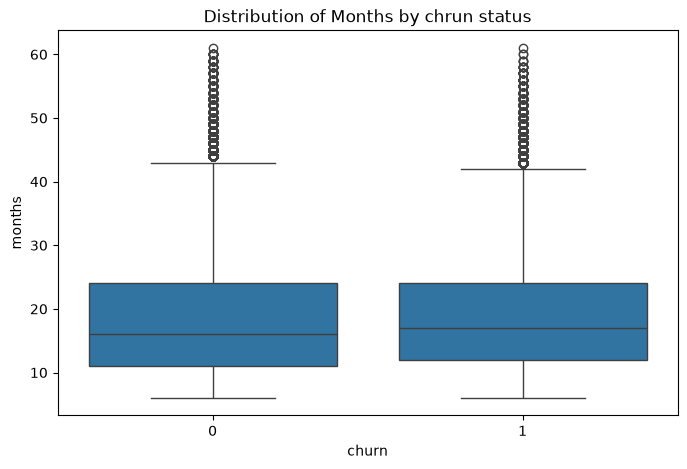

In [118]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='churn', y='months', data=df)
plt.title('Distribution of Months by chrun status')
plt.show()